<a href="https://colab.research.google.com/github/CollisionSeverityPrediction/T13/blob/main/Emma_Sloan_Ass1_T13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pipeline code from T1.1 so this notebook can run standalone

In [ ]:
# importing Python libraries and functions

import pandas as pd
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

import tensorflow as tf
import keras
import random

SEED = 2
np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)
keras.utils.set_random_seed(SEED)

In [ ]:
# Loading the dataset into a pandas dataframe
df = pd.read_csv('/content/drive/MyDrive/Assignment_1/dft-road-casualty-statistics-collision-2024.csv')

/tmp/ipykernel_839/2282544302.py:2: DtypeWarning: Columns (0,2) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('/content/drive/MyDrive/Assignment_1/dft-road-casualty-statistics-collision-2024.csv')


In [ ]:
# drop irrelevant columns such as collision, district and road IDs as advised in brief
df.drop(columns=['collision_index', 'collision_year', 'collision_ref_no',
                  'location_easting_osgr', 'location_northing_osgr',
                  'police_force', 'local_authority_district', 'local_authority_ons_district',
                  'local_authority_highway', 'local_authority_highway_current',
                  'first_road_number', 'junction_detail_historic',
                  'pedestrian_crossing_human_control_historic',
                  'pedestrian_crossing_physical_facilities_historic',
                  'carriageway_hazards_historic', 'second_road_number',
                  'did_police_officer_attend_scene_of_accident',
                  'lsoa_of_accident_location'], inplace=True)

In [ ]:
# save target before dropping column
y = df['collision_severity']

In [ ]:
# drop additional columns
df.drop(columns=['longitude', 'latitude', 'collision_severity',
                  'number_of_casualties', 'enhanced_severity_collision',
                  'collision_injury_based', 'collision_adjusted_severity_serious',
                  'collision_adjusted_severity_slight'], inplace=True)

In [ ]:
# drop columns with high percentage of missing/unknown values that introduce data leakage
df.drop(columns=['special_conditions_at_site', 'junction_control', 'second_road_class', 'trunk_road_flag'], inplace=True)

In [ ]:
# feature engineering for date and time. date becomes month and time becomes time_of_day
df['date'] = pd.to_datetime(df['date'], format='%d/%m/%Y')
df['time'] = pd.to_datetime(df['time'], format='%H:%M')

# Extract month
df['month'] = df['date'].dt.month

# Extract hour, then bucket it into time-of-day categories
df['hour'] = df['time'].dt.hour

def bucket_hour(hour):
    if 0 <= hour < 6:
        return 'night'
    elif 6 <= hour < 10:
        return 'morning_rush'
    elif 10 <= hour < 16:
        return 'daytime'
    elif 16 <= hour < 19:
        return 'evening_rush'
    else:
        return 'evening'

df['time_of_day'] = df['hour'].apply(bucket_hour)

# Drop the now-redundant raw columns
df.drop(columns=['date', 'time', 'hour'], inplace=True)
X = df

In [ ]:
missing_codes = [-1, 9, 99]
cols_needing_replace = ['junction_detail', 'pedestrian_crossing', 'weather_conditions',
                         'carriageway_hazards', 'road_type', 'road_surface_conditions',
                         'light_conditions', 'speed_limit']
X[cols_needing_replace] = X[cols_needing_replace].replace(missing_codes, np.nan)

In [ ]:
# group features
numeric_features = ['number_of_vehicles']

speed_limit_feature = ['speed_limit']

nominal_mode_impute = ['junction_detail', 'pedestrian_crossing', 'weather_conditions',
                        'carriageway_hazards', 'road_type', 'road_surface_conditions',
                        'light_conditions']

nominal_no_missing = ['month', 'time_of_day', 'first_road_class', 'urban_or_rural_area', 'day_of_week']

In [ ]:
# define transformers for each group of features
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

speed_limit_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('scaler', StandardScaler())
])

nominal_mode_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore'))
])

nominal_no_impute_transformer = Pipeline(steps=[
    ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore'))
])

In [ ]:
# combine all transformers
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('speed_limit', speed_limit_transformer, speed_limit_feature),
    ('nom_mode', nominal_mode_transformer, nominal_mode_impute),
    ('nom_no_impute', nominal_no_impute_transformer, nominal_no_missing),
], remainder='drop')

# Set-Up

In [ ]:
# import libraries
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                              precision_recall_fscore_support, confusion_matrix, classification_report)
from sklearn.metrics import roc_auc_score, average_precision_score
import matplotlib.pyplot as plt
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

In [ ]:
# reformulate the collision severity labels
severity_map_binary = {3: 0, 2: 1, 1: 1}
y_binary = y.map(severity_map_binary)

In [ ]:
print(y_binary.value_counts())
pd.crosstab(y, y_binary)

collision_severity
0    75858
1    25069
Name: count, dtype: int64


collision_severity,0,1
collision_severity,,
1,0,1502
2,0,23567
3,75858,0


In [ ]:
# set-up k-fold cross validation using stratified k-fold
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=2)

In [ ]:
# set up a reusable function to gather metrics for fold

def evaluate_fold(y_true, y_pred, y_pred_proba, labels=[0,1]):
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
        'macro_f1': f1_score(y_true, y_pred, average='macro'),
        'per_class_report': classification_report(y_true, y_pred, labels=labels, output_dict=True),
        'confusion_matrix': confusion_matrix(y_true, y_pred, labels=labels),
        'auroc': roc_auc_score(y_true, y_pred_proba),
        'auprc': average_precision_score(y_true, y_pred_proba),
    }

In [ ]:
# metrics for all 5 folds
def overall_metrics(fold_results):

  mean_accuracy = np.mean([r['accuracy'] for r in fold_results])
  std_accuracy = np.std([r['accuracy'] for r in fold_results])

  mean_balanced_acc = np.mean([r['balanced_accuracy'] for r in fold_results])
  std_balanced_acc = np.std([r['balanced_accuracy'] for r in fold_results])

  mean_macro_f1 = np.mean([r['macro_f1'] for r in fold_results])
  std_macro_f1 = np.std([r['macro_f1'] for r in fold_results])

  mean_auroc = np.mean([r['auroc'] for r in fold_results])
  std_auroc = np.std([r['auroc'] for r in fold_results])

  mean_auprc = np.mean([r['auprc'] for r in fold_results])
  std_auprc = np.std([r['auprc'] for r in fold_results])

  total_confusion_matrix = sum(r['confusion_matrix'] for r in fold_results)

  print(f"Accuracy: {mean_accuracy:.3f} ± {std_accuracy:.3f}")
  print(f"Balanced Accuracy: {mean_balanced_acc:.3f} ± {std_balanced_acc:.3f}")
  print(f"Macro-F1: {mean_macro_f1:.3f} ± {std_macro_f1:.3f}")
  print("Confusion Matrix:")
  print(total_confusion_matrix)
  print(f"AUROC: {mean_auroc:.3f} ± {std_auroc:.3f}")
  print(f"AUPRC: {mean_auprc:.3f} ± {std_auprc:.3f}")

  return {
        'accuracy': (mean_accuracy, std_accuracy),
        'balanced_accuracy': (mean_balanced_acc, std_balanced_acc),
        'macro_f1': (mean_macro_f1, std_macro_f1),
        'confusion_matrix': total_confusion_matrix,
        'auroc': (mean_auroc, std_auroc),
        'auprc': (mean_auprc, std_auprc),
    }

In [ ]:
# set up a reusable function to gather per class metrics for each model
def summarize_results(fold_results, class_labels=['Slight', 'Serious_Fatal']):
    summary = {}

    for i, label in enumerate(class_labels):
        precision = np.mean([r['per_class_report'][str(i)]['precision'] for r in fold_results])
        recall = np.mean([r['per_class_report'][str(i)]['recall'] for r in fold_results])
        f1 = np.mean([r['per_class_report'][str(i)]['f1-score'] for r in fold_results])
        summary[f'{label}_precision'] = precision
        summary[f'{label}_recall'] = recall
        summary[f'{label}_f1'] = f1
    return summary


# Majority-Class baseline

In [ ]:
# run the baseline classifier through CV
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline

baseline_fold_results = []

for fold_num, (train_idx, val_idx) in enumerate(skf.split(X, y_binary), start=1):

     X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
     y_train, y_val = y_binary.iloc[train_idx], y_binary.iloc[val_idx]

     # create model for this fold

     baseline = DummyClassifier(strategy='most_frequent')

     baseline_model = Pipeline([
         ('preprocessor', preprocessor),
         ('classifier', baseline)
     ])

     baseline_model.fit(X_train, y_train)
     y_pred = baseline_model.predict(X_val)
     y_pred_proba = baseline_model.predict_proba(X_val)[:, 1]

     # store the metrics for this fold

     baseline_fold_results.append(evaluate_fold(y_val, y_pred, y_pred_proba))

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/m

In [ ]:
baseline_overall_metrics = overall_metrics(baseline_fold_results)
baseline_overall_metrics

Accuracy: 0.752 ± 0.000
Balanced Accuracy: 0.500 ± 0.000
Macro-F1: 0.429 ± 0.000
Confusion Matrix:
[[75858     0]
 [25069     0]]
AUROC: 0.500 ± 0.000
AUPRC: 0.248 ± 0.000


{'accuracy': (np.float64(0.7516125516962744),
  np.float64(1.820718038768583e-05)),
 'balanced_accuracy': (np.float64(0.5), np.float64(0.0)),
 'macro_f1': (np.float64(0.42909749125762), np.float64(5.934188295332734e-06)),
 'confusion_matrix': array([[75858,     0],
        [25069,     0]]),
 'auroc': (np.float64(0.5), np.float64(0.0)),
 'auprc': (np.float64(0.24838744830372556), np.float64(1.820718038768583e-05))}

In [ ]:
baseline_summary = summarize_results(baseline_fold_results)
baseline_summary

{'Slight_precision': np.float64(0.7516125516962744),
 'Slight_recall': np.float64(1.0),
 'Slight_f1': np.float64(0.85819498251524),
 'Serious_Fatal_precision': np.float64(0.0),
 'Serious_Fatal_recall': np.float64(0.0),
 'Serious_Fatal_f1': np.float64(0.0)}

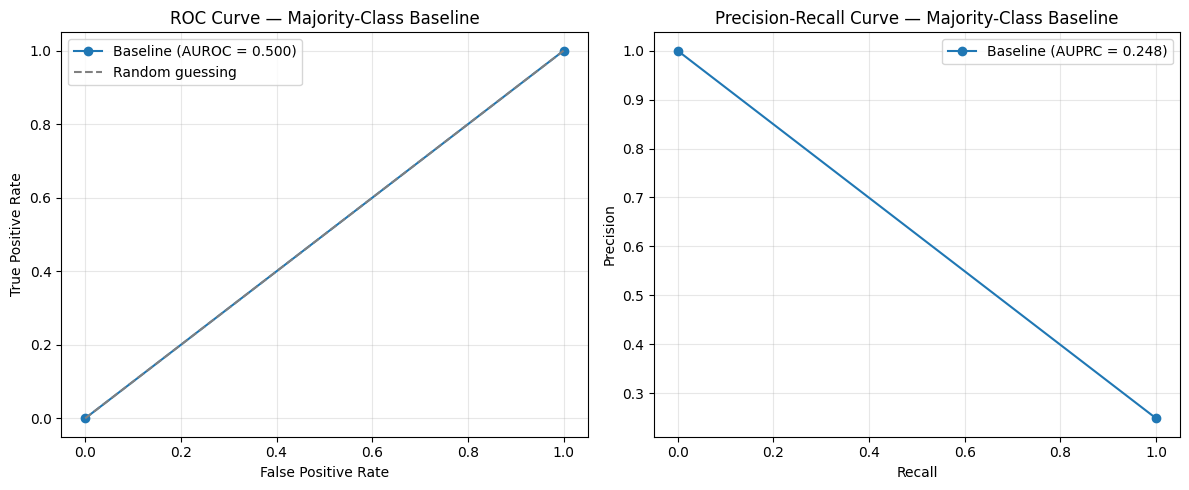

AUROC: 0.500
AUPRC: 0.248


In [ ]:
# Precision-Recall curve and ROC curve for a single representataive fold

from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, average_precision_score

fpr, tpr, roc_thresholds = roc_curve(y_val, y_pred_proba)
precision, recall, pr_thresholds = precision_recall_curve(y_val, y_pred_proba)

auroc = roc_auc_score(y_val, y_pred_proba)
auprc = average_precision_score(y_val, y_pred_proba)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ROC curve
axes[0].plot(fpr, tpr, marker='o', label=f'Baseline (AUROC = {auroc:.3f})')
axes[0].plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guessing')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve — Majority-Class Baseline')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Precision-Recall curve
axes[1].plot(recall, precision, marker='o', label=f'Baseline (AUPRC = {auprc:.3f})')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curve — Majority-Class Baseline')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"AUROC: {auroc:.3f}")
print(f"AUPRC: {auprc:.3f}")

In [ ]:
print(len(np.unique(y_pred_proba)))
print(len(roc_thresholds))
print(len(pr_thresholds))
print(roc_thresholds)
print(pr_thresholds)

1
2
1
[inf  0.]
[0.]


# Binary Logistic Regression Model

Default threshold

In [ ]:
# implement model with class weighting from t1.2, adapted for binary targets

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

log_balanced_fold_results = []

for fold_num, (train_idx, val_idx) in enumerate(skf.split(X, y_binary), start=1):

     X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
     y_train, y_val = y_binary.iloc[train_idx], y_binary.iloc[val_idx]

     # create model for this fold

     log_reg = LogisticRegression(class_weight='balanced', max_iter=1000, solver='lbfgs')

     log_reg_model = Pipeline([
         ('preprocessor', preprocessor),
         ('classifier', log_reg)
     ])

     log_reg_model.fit(X_train, y_train)
     y_pred = log_reg_model.predict(X_val)
     y_pred_proba = log_reg_model.predict_proba(X_val)[:, 1]

     # store the metrics for this fold

     log_balanced_fold_results.append(evaluate_fold(y_val, y_pred, y_pred_proba))

log_balanced_y_val_lastfold = y_val
log_balanced_y_pred_proba_lastfold = y_pred_proba

In [ ]:
log_balanced_overall_metrics = overall_metrics(log_balanced_fold_results)
log_balanced_overall_metrics

Accuracy: 0.587 ± 0.003
Balanced Accuracy: 0.577 ± 0.004
Macro-F1: 0.543 ± 0.003
Confusion Matrix:
[[45363 30495]
 [11143 13926]]
AUROC: 0.603 ± 0.004
AUPRC: 0.326 ± 0.004


{'accuracy': (np.float64(0.5874444416983976), np.float64(0.00287123172608163)),
 'balanced_accuracy': (np.float64(0.5767528201592526),
  np.float64(0.00352498673879263)),
 'macro_f1': (np.float64(0.5431005259696876),
  np.float64(0.0025922250456109036)),
 'confusion_matrix': array([[45363, 30495],
        [11143, 13926]]),
 'auroc': (np.float64(0.6027336785677238), np.float64(0.004129422736040534)),
 'auprc': (np.float64(0.3257247451299134), np.float64(0.00410185690968415))}

In [ ]:
log_balanced_summary = summarize_results(log_balanced_fold_results)
log_balanced_summary

{'Slight_precision': np.float64(0.8028162730467632),
 'Slight_recall': np.float64(0.597998908757938),
 'Slight_f1': np.float64(0.6854164722617004),
 'Serious_Fatal_precision': np.float64(0.31349345719822935),
 'Serious_Fatal_recall': np.float64(0.5555067315605672),
 'Serious_Fatal_f1': np.float64(0.40078457967767483)}

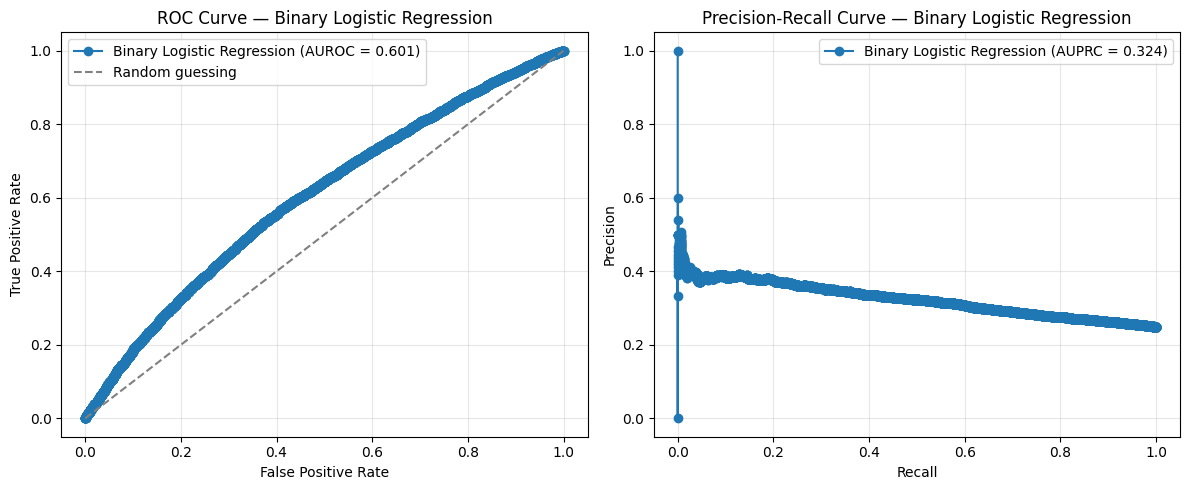

AUROC: 0.601
AUPRC: 0.324


In [ ]:
# Precision-Recall curve and ROC curve for a single representative fold

from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, average_precision_score

fpr, tpr, roc_thresholds = roc_curve(log_balanced_y_val_lastfold, log_balanced_y_pred_proba_lastfold)
precision, recall, pr_thresholds = precision_recall_curve(log_balanced_y_val_lastfold, log_balanced_y_pred_proba_lastfold)

auroc = roc_auc_score(log_balanced_y_val_lastfold, log_balanced_y_pred_proba_lastfold)
auprc = average_precision_score(log_balanced_y_val_lastfold, log_balanced_y_pred_proba_lastfold)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ROC curve
axes[0].plot(fpr, tpr, marker='o', label=f'Binary Logistic Regression (AUROC = {auroc:.3f})')
axes[0].plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guessing')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve — Binary Logistic Regression')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Precision-Recall curve
axes[1].plot(recall, precision, marker='o', label=f'Binary Logistic Regression (AUPRC = {auprc:.3f})')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curve — Binary Logistic Regression')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"AUROC: {auroc:.3f}")
print(f"AUPRC: {auprc:.3f}")

In [ ]:
# list threshold values and their precision recall values
for r, p, t in zip(recall, precision, np.append(pr_thresholds, 1.0)):
    if r % 0.05 < 0.01:
        print(f"Threshold ≈ {t:.3f} | Recall = {r:.3f} | Precision = {p:.3f}")

Threshold ≈ 0.359 | Recall = 0.960 | Precision = 0.255
Threshold ≈ 0.359 | Recall = 0.960 | Precision = 0.255
Threshold ≈ 0.359 | Recall = 0.960 | Precision = 0.255
Threshold ≈ 0.359 | Recall = 0.960 | Precision = 0.255
Threshold ≈ 0.359 | Recall = 0.960 | Precision = 0.255
Threshold ≈ 0.359 | Recall = 0.960 | Precision = 0.255
Threshold ≈ 0.359 | Recall = 0.960 | Precision = 0.255
Threshold ≈ 0.359 | Recall = 0.960 | Precision = 0.255
Threshold ≈ 0.359 | Recall = 0.960 | Precision = 0.255
Threshold ≈ 0.359 | Recall = 0.959 | Precision = 0.255
Threshold ≈ 0.359 | Recall = 0.959 | Precision = 0.255
Threshold ≈ 0.360 | Recall = 0.959 | Precision = 0.255
Threshold ≈ 0.360 | Recall = 0.959 | Precision = 0.255
Threshold ≈ 0.360 | Recall = 0.959 | Precision = 0.255
Threshold ≈ 0.360 | Recall = 0.959 | Precision = 0.255
Threshold ≈ 0.360 | Recall = 0.959 | Precision = 0.255
Threshold ≈ 0.360 | Recall = 0.959 | Precision = 0.255
Threshold ≈ 0.360 | Recall = 0.959 | Precision = 0.255
Threshold 

Custom threshold

In [ ]:
# new improved threshold value 0.442
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

log_threshold_fold_results = []
custom_threshold = 0.442

for fold_num, (train_idx, val_idx) in enumerate(skf.split(X, y_binary), start=1):

     X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
     y_train, y_val = y_binary.iloc[train_idx], y_binary.iloc[val_idx]

     # create model for this fold

     log_reg = LogisticRegression(class_weight='balanced', max_iter=1000, solver='lbfgs')

     log_reg_model = Pipeline([
         ('preprocessor', preprocessor),
         ('classifier', log_reg)
     ])

     log_reg_model.fit(X_train, y_train)
     y_pred_proba = log_reg_model.predict_proba(X_val)[:, 1]
     y_pred_custom = (y_pred_proba >= custom_threshold).astype(int)

     # store the metrics for this fold

     log_threshold_fold_results.append(evaluate_fold(y_val, y_pred_custom, y_pred_proba))


In [ ]:
log_threshold_overall_metrics = overall_metrics(log_threshold_fold_results)
log_threshold_overall_metrics

Accuracy: 0.431 ± 0.003
Balanced Accuracy: 0.555 ± 0.002
Macro-F1: 0.431 ± 0.003
Confusion Matrix:
[[23436 52422]
 [ 4965 20104]]
AUROC: 0.603 ± 0.004
AUPRC: 0.326 ± 0.004


{'accuracy': (np.float64(0.43140093783743805),
  np.float64(0.003209703519847364)),
 'balanced_accuracy': (np.float64(0.5554461970112196),
  np.float64(0.0017673761703836952)),
 'macro_f1': (np.float64(0.4307606586167877),
  np.float64(0.003018603768371192)),
 'confusion_matrix': array([[23436, 52422],
        [ 4965, 20104]]),
 'auroc': (np.float64(0.6027336785677238), np.float64(0.004129422736040534)),
 'auprc': (np.float64(0.3257247451299134), np.float64(0.00410185690968415))}

In [ ]:
log_threshold_summary = summarize_results(log_threshold_fold_results)
log_threshold_summary

{'Slight_precision': np.float64(0.8252214439350245),
 'Slight_recall': np.float64(0.3089456963617659),
 'Slight_f1': np.float64(0.44953704955875773),
 'Serious_Fatal_precision': np.float64(0.277198503902389),
 'Serious_Fatal_recall': np.float64(0.8019466976606733),
 'Serious_Fatal_f1': np.float64(0.4119842676748178)}

# DNN model

Default threshold

In [ ]:
# DNN CV and default threshold

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.optimizers import Adam

binary_dnn_fold_results = []

for binary_dnn_fold_num, (binary_dnn_train_idx, binary_dnn_val_idx) in enumerate(skf.split(X, y_binary), start=1):

    tf.random.set_seed(SEED)

    binary_dnn_X_train, binary_dnn_X_val = X.iloc[binary_dnn_train_idx], X.iloc[binary_dnn_val_idx]
    binary_dnn_y_train, binary_dnn_y_val = y_binary.iloc[binary_dnn_train_idx], y_binary.iloc[binary_dnn_val_idx]

    binary_dnn_X_train_transformed = preprocessor.fit_transform(binary_dnn_X_train, binary_dnn_y_train)
    binary_dnn_X_val_transformed = preprocessor.transform(binary_dnn_X_val)

    if hasattr(binary_dnn_X_train_transformed, 'toarray'):
        binary_dnn_X_train_transformed = binary_dnn_X_train_transformed.toarray()
    if hasattr(binary_dnn_X_val_transformed, 'toarray'):
        binary_dnn_X_val_transformed = binary_dnn_X_val_transformed.toarray()

    binary_dnn_n_features = binary_dnn_X_train_transformed.shape[1]

    # class weights
    binary_dnn_weights = compute_class_weight('balanced', classes=np.array([0, 1]), y=binary_dnn_y_train)
    binary_dnn_class_weight_dict = dict(zip([0, 1], binary_dnn_weights))

    # build model
    binary_dnn_model = keras.Sequential([
        keras.Input(shape=(binary_dnn_n_features,)),
        keras.layers.Dense(64, activation='relu'),
        keras.layers.Dense(32, activation='relu'),
        keras.layers.Dense(1, activation='sigmoid')
    ])

    binary_dnn_adam = Adam(learning_rate=0.001)
    binary_dnn_model.compile(optimizer=binary_dnn_adam, loss='binary_crossentropy', metrics=['accuracy'])

    binary_dnn_early_stop = keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=10, restore_best_weights=True
    )

    binary_dnn_history = binary_dnn_model.fit(
        binary_dnn_X_train_transformed, binary_dnn_y_train,
        validation_data=(binary_dnn_X_val_transformed, binary_dnn_y_val),
        epochs=100, batch_size=32,
        class_weight=binary_dnn_class_weight_dict,
        callbacks=[binary_dnn_early_stop],
        verbose=1
    )

    binary_dnn_y_pred_probs = binary_dnn_model.predict(binary_dnn_X_val_transformed, verbose=0)
    binary_dnn_y_pred_proba = binary_dnn_y_pred_probs.ravel()
    binary_dnn_y_pred = (binary_dnn_y_pred_proba > 0.5).astype(int)

    binary_dnn_fold_result = evaluate_fold(binary_dnn_y_val, binary_dnn_y_pred, binary_dnn_y_pred_proba)
    binary_dnn_fold_results.append(binary_dnn_fold_result)

    print(f"Fold {binary_dnn_fold_num}: macro-F1 = {binary_dnn_fold_result['macro_f1']:.3f}, "
          f"AUROC = {binary_dnn_fold_result['auroc']:.3f} "
          f"(epochs run: {len(binary_dnn_history.history['loss'])})")

binary_dnn_y_val_lastfold = binary_dnn_y_val
binary_dnn_y_pred_proba_lastfold = binary_dnn_y_pred_proba

print(f"\nAverage macro-F1: {np.mean([r['macro_f1'] for r in binary_dnn_fold_results]):.3f} "
      f"± {np.std([r['macro_f1'] for r in binary_dnn_fold_results]):.3f}")

Epoch 1/100
2524/2524 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.5881 - loss: 0.6766 - val_accuracy: 0.5714 - val_loss: 0.6855
Epoch 2/100
2524/2524 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - accuracy: 0.5993 - loss: 0.6704 - val_accuracy: 0.5670 - val_loss: 0.6837
Epoch 3/100
2524/2524 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.6017 - loss: 0.6677 - val_accuracy: 0.5604 - val_loss: 0.6844
Epoch 4/100
2524/2524 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - accuracy: 0.6022 - loss: 0.6654 - val_accuracy: 0.5554 - val_loss: 0.6851
Epoch 5/100
2524/2524 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.6043 - loss: 0.6630 - val_accuracy: 0.5566 - val_loss: 0.6838
Epoch 6/100
2524/2524 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - accuracy: 0.6066 - loss: 0.6607 - val_accuracy: 0.5520 - val_loss: 0.6859
Epoch 7/100
2524/2524 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.6074 - loss: 0.6583 - val_accuracy: 0.5490 - val_loss: 0.6883
Epoch 8/100
2524/2524 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - accuracy: 0.6087 - loss: 0

In [ ]:
binary_dnn_overall_metrics = overall_metrics(binary_dnn_fold_results)
binary_dnn_overall_metrics

Accuracy: 0.573 ± 0.023
Balanced Accuracy: 0.585 ± 0.005
Macro-F1: 0.538 ± 0.011
Confusion Matrix:
[[42559 33299]
 [ 9793 15276]]
AUROC: 0.616 ± 0.007
AUPRC: 0.336 ± 0.004


{'accuracy': (np.float64(0.5730381776945302),
  np.float64(0.022757835383937584)),
 'balanced_accuracy': (np.float64(0.5851944167675264),
  np.float64(0.005478757412676203)),
 'macro_f1': (np.float64(0.5384104441964539),
  np.float64(0.010614049717959985)),
 'confusion_matrix': array([[42559, 33299],
        [ 9793, 15276]]),
 'auroc': (np.float64(0.615782991571953), np.float64(0.006599365652940777)),
 'auprc': (np.float64(0.33615960127451505), np.float64(0.004052507111052834))}

In [ ]:
binary_dnn_summary = summarize_results(binary_dnn_fold_results)
binary_dnn_summary

{'Slight_precision': np.float64(0.8137391394674112),
 'Slight_recall': np.float64(0.5610346939867494),
 'Slight_f1': np.float64(0.6626832983589599),
 'Serious_Fatal_precision': np.float64(0.3149214343306606),
 'Serious_Fatal_recall': np.float64(0.6093541395483032),
 'Serious_Fatal_f1': np.float64(0.41413759003394784)}

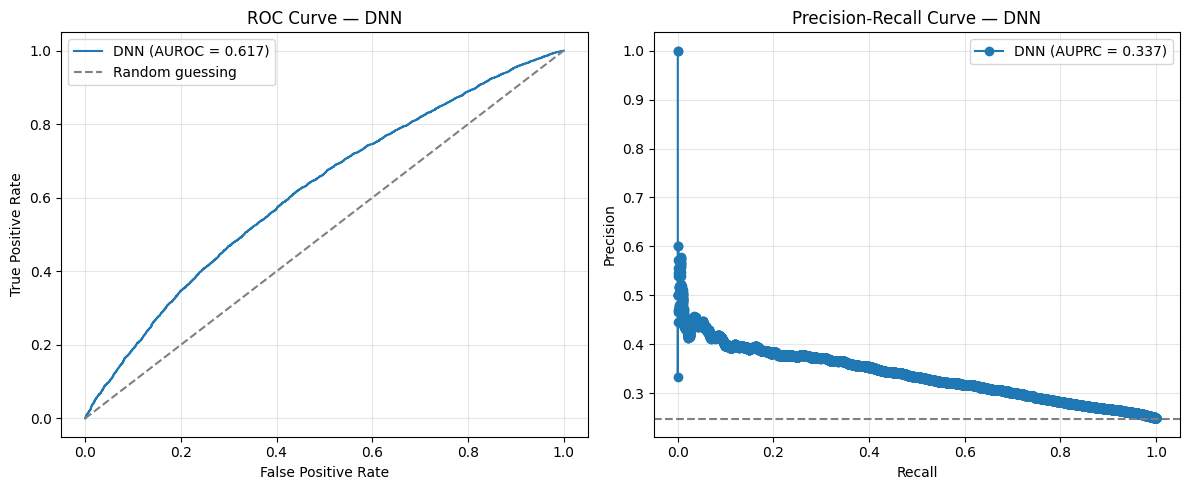

AUROC: 0.617
AUPRC: 0.337


In [ ]:
# Precision-Recall curve and ROC curve for a single representative fold

from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, average_precision_score

fpr, tpr, roc_thresholds = roc_curve(binary_dnn_y_val_lastfold, binary_dnn_y_pred_proba_lastfold)
precision, recall, pr_thresholds = precision_recall_curve(binary_dnn_y_val_lastfold, binary_dnn_y_pred_proba_lastfold)

auroc = roc_auc_score(binary_dnn_y_val_lastfold, binary_dnn_y_pred_proba_lastfold)
auprc = average_precision_score(binary_dnn_y_val_lastfold, binary_dnn_y_pred_proba_lastfold)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ROC curve
axes[0].plot(fpr, tpr, label=f'DNN (AUROC = {auroc:.3f})')
axes[0].plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guessing')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve — DNN')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Precision-Recall curve
axes[1].plot(recall, precision, marker='o', label=f'DNN (AUPRC = {auprc:.3f})')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curve — DNN')
axes[1].legend()
axes[1].grid(alpha=0.3)
axes[1].axhline(y=0.248, linestyle='--', color='gray', label='No-skill baseline')

plt.tight_layout()
plt.show()

print(f"AUROC: {auroc:.3f}")
print(f"AUPRC: {auprc:.3f}")

In [ ]:
# list thresholds and their precision recall values
for r, p, t in zip(recall, precision, np.append(pr_thresholds, 1.0)):
    if r % 0.05 < 0.01:
        print(f"Threshold ≈ {t:.3f} | Recall = {r:.3f} | Precision = {p:.3f}")

Threshold ≈ 0.322 | Recall = 0.960 | Precision = 0.259
Threshold ≈ 0.322 | Recall = 0.960 | Precision = 0.259
Threshold ≈ 0.322 | Recall = 0.960 | Precision = 0.259
Threshold ≈ 0.322 | Recall = 0.960 | Precision = 0.259
Threshold ≈ 0.322 | Recall = 0.960 | Precision = 0.259
Threshold ≈ 0.322 | Recall = 0.960 | Precision = 0.259
Threshold ≈ 0.322 | Recall = 0.960 | Precision = 0.259
Threshold ≈ 0.322 | Recall = 0.960 | Precision = 0.259
Threshold ≈ 0.322 | Recall = 0.960 | Precision = 0.259
Threshold ≈ 0.322 | Recall = 0.960 | Precision = 0.259
Threshold ≈ 0.322 | Recall = 0.960 | Precision = 0.259
Threshold ≈ 0.322 | Recall = 0.959 | Precision = 0.259
Threshold ≈ 0.322 | Recall = 0.959 | Precision = 0.259
Threshold ≈ 0.322 | Recall = 0.959 | Precision = 0.259
Threshold ≈ 0.322 | Recall = 0.959 | Precision = 0.259
Threshold ≈ 0.322 | Recall = 0.959 | Precision = 0.259
Threshold ≈ 0.322 | Recall = 0.959 | Precision = 0.259
Threshold ≈ 0.322 | Recall = 0.959 | Precision = 0.259
Threshold 

Custom threshold

In [ ]:
# DNN model with custom threshold of 0.417

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.optimizers import Adam

binary_dnn_thresh_fold_results = []

for binary_dnn_thresh_fold_num, (binary_dnn_thresh_train_idx, binary_dnn_thresh_val_idx) in enumerate(skf.split(X, y_binary), start=1):

    binary_dnn_thresh_X_train, binary_dnn_thresh_X_val = X.iloc[binary_dnn_thresh_train_idx], X.iloc[binary_dnn_thresh_val_idx]
    binary_dnn_thresh_y_train, binary_dnn_thresh_y_val = y_binary.iloc[binary_dnn_thresh_train_idx], y_binary.iloc[binary_dnn_thresh_val_idx]

    binary_dnn_thresh_X_train_transformed = preprocessor.fit_transform(binary_dnn_thresh_X_train, binary_dnn_thresh_y_train)
    binary_dnn_thresh_X_val_transformed = preprocessor.transform(binary_dnn_thresh_X_val)

    if hasattr(binary_dnn_thresh_X_train_transformed, 'toarray'):
        binary_dnn_thresh_X_train_transformed = binary_dnn_thresh_X_train_transformed.toarray()
    if hasattr(binary_dnn_thresh_X_val_transformed, 'toarray'):
        binary_dnn_thresh_X_val_transformed = binary_dnn_thresh_X_val_transformed.toarray()

    binary_dnn_thresh_n_features = binary_dnn_thresh_X_train_transformed.shape[1]

    binary_dnn_thresh_weights = compute_class_weight('balanced', classes=np.array([0, 1]), y=binary_dnn_thresh_y_train)
    binary_dnn_thresh_class_weight_dict = dict(zip([0, 1], binary_dnn_thresh_weights))

    binary_dnn_thresh_model = keras.Sequential([
        keras.Input(shape=(binary_dnn_thresh_n_features,)),
        keras.layers.Dense(64, activation='relu'),
        keras.layers.Dense(32, activation='relu'),
        keras.layers.Dense(1, activation='sigmoid')
    ])

    binary_dnn_thresh_adam = Adam(learning_rate=0.001)
    binary_dnn_thresh_model.compile(optimizer=binary_dnn_thresh_adam, loss='binary_crossentropy', metrics=['accuracy'])

    binary_dnn_thresh_early_stop = keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=10, restore_best_weights=True
    )

    binary_dnn_thresh_history = binary_dnn_thresh_model.fit(
        binary_dnn_thresh_X_train_transformed, binary_dnn_thresh_y_train,
        validation_data=(binary_dnn_thresh_X_val_transformed, binary_dnn_thresh_y_val),
        epochs=100, batch_size=32,
        class_weight=binary_dnn_thresh_class_weight_dict,
        callbacks=[binary_dnn_thresh_early_stop],
        verbose=0
    )

    binary_dnn_thresh_y_pred_probs = binary_dnn_thresh_model.predict(binary_dnn_thresh_X_val_transformed, verbose=0)
    binary_dnn_thresh_y_pred_proba = binary_dnn_thresh_y_pred_probs.ravel()
    binary_dnn_thresh_y_pred = (binary_dnn_thresh_y_pred_proba > 0.417).astype(int)

    binary_dnn_thresh_fold_result = evaluate_fold(binary_dnn_thresh_y_val, binary_dnn_thresh_y_pred, binary_dnn_thresh_y_pred_proba)
    binary_dnn_thresh_fold_results.append(binary_dnn_thresh_fold_result)

    print(f"Fold {binary_dnn_thresh_fold_num}: macro-F1 = {binary_dnn_thresh_fold_result['macro_f1']:.3f}, "
          f"AUROC = {binary_dnn_thresh_fold_result['auroc']:.3f} "
          f"(epochs run: {len(binary_dnn_thresh_history.history['loss'])})")

print(f"\nAverage macro-F1: {np.mean([r['macro_f1'] for r in binary_dnn_thresh_fold_results]):.3f} "
      f"± {np.std([r['macro_f1'] for r in binary_dnn_thresh_fold_results]):.3f}")

Fold 1: macro-F1 = 0.407, AUROC = 0.614 (epochs run: 17)
Fold 2: macro-F1 = 0.374, AUROC = 0.615 (epochs run: 13)
Fold 3: macro-F1 = 0.460, AUROC = 0.615 (epochs run: 12)
Fold 4: macro-F1 = 0.406, AUROC = 0.614 (epochs run: 16)
Fold 5: macro-F1 = 0.436, AUROC = 0.619 (epochs run: 12)

Average macro-F1: 0.417 ± 0.029


In [ ]:
binary_dnn_thresh_overall_metrics = overall_metrics(binary_dnn_thresh_fold_results)
binary_dnn_thresh_overall_metrics

Accuracy: 0.418 ± 0.029
Balanced Accuracy: 0.557 ± 0.008
Macro-F1: 0.417 ± 0.029
Confusion Matrix:
[[21305 54553]
 [ 4190 20879]]
AUROC: 0.615 ± 0.002
AUPRC: 0.336 ± 0.004


{'accuracy': (np.float64(0.4179659746473231),
  np.float64(0.029398369085276817)),
 'balanced_accuracy': (np.float64(0.556856411814189),
  np.float64(0.007556647552077247)),
 'macro_f1': (np.float64(0.4166564115817854),
  np.float64(0.029035831595660738)),
 'confusion_matrix': array([[21305, 54553],
        [ 4190, 20879]]),
 'auroc': (np.float64(0.6153069243999874), np.float64(0.0020291698444345075)),
 'auprc': (np.float64(0.3355783573964407), np.float64(0.003663458609072999))}

In [ ]:
binary_dnn_thresh_summary = summarize_results(binary_dnn_thresh_fold_results)
binary_dnn_thresh_summary

{'Slight_precision': np.float64(0.8366371977731196),
 'Slight_recall': np.float64(0.28085386919550376),
 'Slight_f1': np.float64(0.4177406947035073),
 'Serious_Fatal_precision': np.float64(0.2771442903300415),
 'Serious_Fatal_recall': np.float64(0.8328589544328742),
 'Serious_Fatal_f1': np.float64(0.4155721284600634)}

# Summary of results accross all models

In [ ]:
# Comparison of all T1.3 models

import pandas as pd

rows = {
    'Baseline (0.5)': {**baseline_overall_metrics, **baseline_summary},
    'Logistic Regression (0.5)': {**log_balanced_overall_metrics, **log_balanced_summary},
    'Logistic Regression (threshold 0.442)': {**log_threshold_overall_metrics, **log_threshold_summary},
    'DNN (0.5)': {**binary_dnn_overall_metrics, **binary_dnn_summary},
    'DNN (threshold 0.417)': {**binary_dnn_thresh_overall_metrics, **binary_dnn_thresh_summary},
}

metric_columns = [
    'accuracy', 'balanced_accuracy', 'macro_f1', 'auroc', 'auprc',
    'Slight_precision', 'Slight_recall', 'Slight_f1',
    'Serious_Fatal_precision', 'Serious_Fatal_recall', 'Serious_Fatal_f1',
]

comparison = pd.DataFrame(rows).T
comparison = comparison[metric_columns]

for col in ['accuracy', 'balanced_accuracy', 'macro_f1', 'auroc', 'auprc']:
    comparison[col] = comparison[col].apply(lambda x: x[0] if isinstance(x, tuple) else x)

comparison = comparison.round(3)
comparison

,accuracy,balanced_accuracy,macro_f1,auroc,auprc,Slight_precision,Slight_recall,Slight_f1,Serious_Fatal_precision,Serious_Fatal_recall,Serious_Fatal_f1
Baseline (0.5),0.752,0.500,0.429,0.500,0.248,0.751613,1.0,0.858195,0.0,0.0,0.0
Logistic Regression (0.5),0.587,0.577,0.543,0.603,0.326,0.802816,0.597999,0.685416,0.313493,0.555507,0.400785
Logistic Regression (threshold 0.442),0.431,0.555,0.431,0.603,0.326,0.825221,0.308946,0.449537,0.277199,0.801947,0.411984
DNN (0.5),0.573,0.585,0.538,0.616,0.336,0.813739,0.561035,0.662683,0.314921,0.609354,0.414138
DNN (threshold 0.417),0.418,0.557,0.417,0.615,0.336,0.836637,0.280854,0.417741,0.277144,0.832859,0.415572


In [ ]:
confusion_matrices = {
    'Baseline (0.5)': baseline_overall_metrics['confusion_matrix'],
    'Logistic Regression (0.5)': log_balanced_overall_metrics['confusion_matrix'],
    'Logistic Regression (threshold 0.442)': log_threshold_overall_metrics['confusion_matrix'],
    'DNN (0.5)': binary_dnn_overall_metrics['confusion_matrix'],
    'DNN (threshold 0.417)': binary_dnn_thresh_overall_metrics['confusion_matrix'],
}

class_labels = ['Slight', 'Serious/Fatal']

for model_name, cm in confusion_matrices.items():
    print(f"\n{model_name} — Confusion Matrix (summed across 5 folds)")
    cm_df = pd.DataFrame(cm, index=[f'Actual {c}' for c in class_labels],
                              columns=[f'Predicted {c}' for c in class_labels])
    print(cm_df)


Baseline (0.5) — Confusion Matrix (summed across 5 folds)
                      Predicted Slight  Predicted Serious/Fatal
Actual Slight                    75858                        0
Actual Serious/Fatal             25069                        0

Logistic Regression (0.5) — Confusion Matrix (summed across 5 folds)
                      Predicted Slight  Predicted Serious/Fatal
Actual Slight                    45363                    30495
Actual Serious/Fatal             11143                    13926

Logistic Regression (threshold 0.442) — Confusion Matrix (summed across 5 folds)
                      Predicted Slight  Predicted Serious/Fatal
Actual Slight                    23436                    52422
Actual Serious/Fatal              4965                    20104

DNN (0.5) — Confusion Matrix (summed across 5 folds)
                      Predicted Slight  Predicted Serious/Fatal
Actual Slight                    42559                    33299
Actual Serious/Fatal           